In [ ]:
%%bash
set -e

# Jika ~/.kaggle ada tapi BUKAN direktori → backup
if [ -e "$HOME/.kaggle" ] && [ ! -d "$HOME/.kaggle" ]; then
  echo "Found $HOME/.kaggle as a file; backing up..."
  mv "$HOME/.kaggle" "$HOME/.kaggle.bak.$(date +%s)"
fi

# Buat direktori yang benar
mkdir -p "$HOME/.kaggle"

# Salin kaggle.json (pastikan ada di /content)
SRC_JSON="/content/kaggle.json"
if [ -f "$SRC_JSON" ]; then
  cp "$SRC_JSON" "$HOME/.kaggle/kaggle.json"
  chmod 600 "$HOME/.kaggle/kaggle.json"
  echo "OK: kaggle.json terset di $HOME/.kaggle (perm 600)."
else
  echo "WARNING: $SRC_JSON tidak ditemukan. Upload kaggle.json ke /content lalu ulangi."
fi

# Verifikasi
ls -ld "$HOME/.kaggle"
ls -l "$HOME/.kaggle"

OK: kaggle.json terset di /root/.kaggle (perm 600).
drwxr-xr-x 2 root root 4096 Feb 13 13:44 /root/.kaggle
total 4
-rw------- 1 root root 65 Feb 13 13:44 kaggle.json


In [ ]:
!pip -q install kaggle

In [ ]:
!cp kaggle.json ~/.kaggle

In [ ]:
!chmod 600 ~/.kaggle/kaggle.json

In [ ]:
!kaggle datasets list

ref                                                             title                                                   size  lastUpdated                 downloadCount  voteCount  usabilityRating  
--------------------------------------------------------------  ------------------------------------------------  ----------  --------------------------  -------------  ---------  ---------------  
saidaminsaidaxmadov/chocolate-sales                             Chocolate Sales                                       468320  2026-01-04 14:23:35.490000          19016        339  1.0              
aliiihussain/amazon-sales-dataset                               Amazon_Sales_Dataset                                 1297759  2026-02-01 11:37:12.353000           4453         82  1.0              
ashrafkhetran/the-movies-database-tmdb-1950-2025                The Movies database (TMDB) 1950-2025                    4897  2026-02-09 05:35:40.533000           1144         26  1.0              
ayeshasidd

In [ ]:
!mkdir -p /content/BraTS20_RAW
!kaggle datasets download -d awsaf49/brats20-dataset-training-validation -p /content/BraTS20_RAW --unzip
!find /content/BraTS20_RAW -type f -name "*_seg.nii.gz" | head -n 8


Dataset URL: https://www.kaggle.com/datasets/awsaf49/brats20-dataset-training-validation
License(s): CC0-1.0
User cancelled operation
^C


In [ ]:
!find /content/brats_processed -type f -name "*.npz" -print -delete

find: ‘/content/brats_processed’: No such file or directory


In [ ]:
%%writefile preprocess_brats.py
# preprocess_brats.py (FINAL, FLOPs-safe & Dice-optimized)
import os
import numpy as np
import nibabel as nib
from pathlib import Path
from skimage.transform import resize as sk_resize

EPS = 1e-6

SAVE_FP16 = os.environ.get("SAVE_FP16", "1")
DROP_DED  = os.environ.get("DROP_DED", "0")
ROUND_TO_MULT = int(os.environ.get("ROUND_TO_MULT", "8"))

def load_nii(p):
    return nib.load(str(p)).get_fdata(dtype=np.float32)

def robust_clip(x, m, lo=0.5, hi=99.5):
    v = x[m > 0]
    if v.size == 0:
        return x
    return np.clip(x, np.percentile(v, lo), np.percentile(v, hi))

def zscore(x, m):
    v = x[m > 0]
    mu = v.mean() if v.size else 0.0
    sd = v.std() if v.size else 1.0
    return (x - mu) / (sd + EPS)

def delta(a, b):
    return (a - b) / (a + b + EPS)

def get_bbox(mask, margin):
    idx = np.nonzero(mask)
    if len(idx[0]) == 0:
        return (0, *mask.shape)
    z0, y0, x0 = [int(i.min()) for i in idx]
    z1, y1, x1 = [int(i.max()) + 1 for i in idx]
    return (
        max(0, z0 - margin),
        min(mask.shape[0], z1 + margin),
        max(0, y0 - margin),
        min(mask.shape[1], y1 + margin),
        max(0, x0 - margin),
        min(mask.shape[2], x1 + margin),
    )

def resize_vol(x, shape, order):
    return sk_resize(
        x, shape,
        order=order,
        preserve_range=True,
        anti_aliasing=(order > 0)
    )

def find_modalities(case):
    def g(p): return list(case.glob(p))
    return (
        g("*_flair.nii*")[0],
        g("*_t1.nii*")[0],
        g("*_t1ce.nii*")[0],
        g("*_t2.nii*")[0],
        g("*_seg.nii*")[0],
    )

def process_case(case_dir, out_dir):
    f, t1p, t1cep, t2p, segp = find_modalities(case_dir)
    flair, t1, t1ce, t2 = map(load_nii, [f, t1p, t1cep, t2p])
    seg = load_nii(segp).astype(np.uint8)
    seg[seg == 4] = 3

    brain = (flair > 0) | (t1 > 0) | (t1ce > 0) | (t2 > 0)
    tumor = seg > 0

    margin = 12 if (seg == 1).sum() < 500 else 8
    if tumor.any():
        bbox = get_bbox(tumor, margin)
    else:
        bbox = get_bbox(brain, margin=4)

    z0,z1,y0,y1,x0,x1 = bbox
    flair,t1,t1ce,t2,seg = [
        v[z0:z1,y0:y1,x0:x1]
        for v in (flair,t1,t1ce,t2,seg)
    ]
    brain = brain[z0:z1,y0:y1,x0:x1]

    flair = zscore(robust_clip(flair,brain), brain)
    t1    = zscore(robust_clip(t1,brain), brain)
    t1ce  = zscore(robust_clip(t1ce,brain), brain)
    t2    = zscore(robust_clip(t2,brain), brain)

    dce = delta(t1ce, t1)
    ded = delta(flair, t2) if DROP_DED != "1" else None

    # === FINAL CHANNEL SET (5) ===
    chans = [t1ce, t2, flair, dce]
    if ded is not None:
        chans.append(ded)

    img = np.stack(chans, 0)

    img = img.astype(np.float16 if SAVE_FP16=="1" else np.float32)

    out_dir.mkdir(parents=True, exist_ok=True)
    np.savez_compressed(
        out_dir / f"{case_dir.name}.npz",
        image=img,
        label=seg.astype(np.uint8),
        bbox=np.array(bbox),
        case_id=case_dir.name
    )

def process_root(raw, out):
    raw, out = Path(raw), Path(out)
    cases = sorted({p.parent for p in raw.rglob("*_seg.nii*")})
    for c in cases:
        try:
            process_case(c, out)
            print("[OK]", c.name)
        except Exception as e:
            print("[SKIP]", c.name, e)

if __name__ == "__main__":
    RAW = os.environ.get("BRATS_RAW")
    OUT = os.environ.get("BRATS_OUT")
    process_root(RAW, OUT)


Writing preprocess_brats.py


In [ ]:
# ================== ENV SETUP (FINAL RECOMMENDED) ==================
import os

# Path dataset
os.environ["BRATS_RAW"] = "/content/BraTS20_RAW"
os.environ["BRATS_OUT"] = "/content/brats_processed"

# ================== PREPROCESS OPTIONS ==================
# Simpan image sebagai FP16 (hemat RAM, aman)
os.environ["SAVE_FP16"] = "1"

# Jangan drop ΔED (penting untuk ED vs NCR)
os.environ["DROP_DED"]  = "0"

# >>> PENTING: JANGAN resize volume penuh <<<
# Resize global menurunkan Dice NCR
os.environ["RESIZE_TO"] = ""
os.environ["RESIZE_SCALE"] = ""

# Pastikan dimensi kompatibel UNet (multiple of 8)
os.environ["ROUND_TO_MULT"] = "8"

print("ENV SETUP DONE")



ENV SETUP DONE


In [ ]:
# ================== RUN PREPROCESS ==================
!python preprocess_brats.py


[OK] BraTS20_Training_001
[OK] BraTS20_Training_002
[OK] BraTS20_Training_003
[OK] BraTS20_Training_004
[OK] BraTS20_Training_005
/content/preprocess_brats.py:102: RuntimeWarning: overflow encountered in cast
  img = img.astype(np.float16 if SAVE_FP16=="1" else np.float32)
[OK] BraTS20_Training_006
[OK] BraTS20_Training_007
[OK] BraTS20_Training_008
[OK] BraTS20_Training_009
[OK] BraTS20_Training_010
[OK] BraTS20_Training_011
[OK] BraTS20_Training_012
[OK] BraTS20_Training_013
[OK] BraTS20_Training_014
[OK] BraTS20_Training_015
[OK] BraTS20_Training_016
[OK] BraTS20_Training_017
[OK] BraTS20_Training_018
[OK] BraTS20_Training_019
[OK] BraTS20_Training_020
[OK] BraTS20_Training_021
[OK] BraTS20_Training_022
[OK] BraTS20_Training_023
[OK] BraTS20_Training_024
[OK] BraTS20_Training_025
[OK] BraTS20_Training_026
[OK] BraTS20_Training_027
[OK] BraTS20_Training_028
[OK] BraTS20_Training_029
[OK] BraTS20_Training_030
[OK] BraTS20_Training_031
[OK] BraTS20_Training_032
[OK] BraTS20_Training_03

In [ ]:
# ================== CREATE SPLIT FILE ==================
import json, random
from pathlib import Path

DATA_DIR = Path("/content/brats_processed")
OUT_SPLIT = DATA_DIR / "splits_fixed.json"

ids = sorted([p.stem for p in DATA_DIR.glob("*.npz")])

random.seed(13)
random.shuffle(ids)

N = len(ids)
n_train = int(0.7 * N)
n_val   = int(0.1 * N)

split = {
    "train": ids[:n_train],
    "val":   ids[n_train:n_train+n_val],
    "test":  ids[n_train+n_val:]
}

with open(OUT_SPLIT, "w") as f:
    json.dump(split, f, indent=2)

print("Split saved to:", OUT_SPLIT)
print({k: len(v) for k,v in split.items()})


Split saved to: /content/brats_processed/splits_fixed.json
{'train': 257, 'val': 36, 'test': 75}


In [ ]:
%%writefile /content/brats_dataset.py
import os
import numpy as np
import torch
from torch.utils.data import Dataset, DataLoader

class BraTSPatchDataset(Dataset):
    def __init__(self, root, patch):
        self.files = sorted([
            os.path.join(root, f)
            for f in os.listdir(root)
            if f.endswith(".npz")
        ])
        self.patch = patch

    def __len__(self):
        return len(self.files)

    def __getitem__(self, i):
        data = np.load(self.files[i])
        x = data["image"]
        y = data["label"]

        D,H,W = y.shape
        p = self.patch

        z = np.random.randint(0, max(1, D-p+1))
        y0 = np.random.randint(0, max(1, H-p+1))
        x0 = np.random.randint(0, max(1, W-p+1))

        return (
            torch.from_numpy(x[:,z:z+p,y0:y0+p,x0:x0+p]).float(),
            torch.from_numpy(y[z:z+p,y0:y0+p,x0:x0+p]).long()
        )

def make_loader(root, batch_size=1, patch=64, shuffle=True):
    ds = BraTSPatchDataset(root, patch)
    return DataLoader(ds, batch_size=batch_size, shuffle=shuffle, num_workers=2)


Writing /content/brats_dataset.py


In [ ]:
%%writefile /content/lightunet_transformer3d.py
import torch
import torch.nn as nn
import torch.nn.functional as F

# ======================================================
# ULTRA SAFE SIZE MATCHING
# ======================================================
def match_size(enc, target):
    """
    Match spatial size enc -> target
    Aman untuk crop maupun pad
    """
    _, _, D, H, W = target.shape
    _, _, d, h, w = enc.shape

    # If larger → center crop
    if d > D:
        ds = (d - D) // 2
        enc = enc[:, :, ds:ds + D, :, :]
    if h > H:
        hs = (h - H) // 2
        enc = enc[:, :, :, hs:hs + H, :]
    if w > W:
        ws = (w - W) // 2
        enc = enc[:, :, :, :, ws:ws + W]

    # If smaller → pad
    if enc.shape[2] < D or enc.shape[3] < H or enc.shape[4] < W:
        pad_d = D - enc.shape[2]
        pad_h = H - enc.shape[3]
        pad_w = W - enc.shape[4]

        enc = F.pad(
            enc,
            [
                pad_w // 2, pad_w - pad_w // 2,
                pad_h // 2, pad_h - pad_h // 2,
                pad_d // 2, pad_d - pad_d // 2
            ]
        )

    return enc


# ======================================================
# BASIC BLOCK
# ======================================================
class ConvBlock(nn.Module):
    def __init__(self, cin, cout):
        super().__init__()
        self.net = nn.Sequential(
            nn.Conv3d(cin, cout, 3, padding=1, bias=False),
            nn.InstanceNorm3d(cout),
            nn.LeakyReLU(0.1, inplace=True),

            nn.Conv3d(cout, cout, 3, padding=1, bias=False),
            nn.InstanceNorm3d(cout),
            nn.LeakyReLU(0.1, inplace=True),
        )

    def forward(self, x):
        return self.net(x)


# ======================================================
# LIGHT TRANSFORMER
# ======================================================
class SimpleTransformer3D(nn.Module):
    def __init__(self, dim):
        super().__init__()
        self.norm1 = nn.InstanceNorm3d(dim)
        self.attn = nn.Conv3d(dim, dim, 1)

        self.norm2 = nn.InstanceNorm3d(dim)
        self.ffn = nn.Sequential(
            nn.Conv3d(dim, dim * 2, 1),
            nn.GELU(),
            nn.Conv3d(dim * 2, dim, 1),
        )

    def forward(self, x):
        x = x + self.attn(self.norm1(x))
        x = x + self.ffn(self.norm2(x))
        return x


# ======================================================
# LIGHT UNET 3D (FULLY SAFE VERSION)
# ======================================================
class LightUNet3D(nn.Module):
    def __init__(self, in_ch=5, base=32, num_classes=4):
        super().__init__()

        # Encoder
        self.enc1 = ConvBlock(in_ch, base)
        self.enc2 = ConvBlock(base, base * 2)
        self.enc3 = ConvBlock(base * 2, base * 4)
        self.enc4 = ConvBlock(base * 4, base * 8)

        # Pooling
        self.pool = nn.MaxPool3d(2, ceil_mode=True)

        # Bottleneck
        self.bottleneck = SimpleTransformer3D(base * 8)

        # Decoder
        self.up3 = nn.ConvTranspose3d(base * 8, base * 4, 2, stride=2)
        self.dec3 = ConvBlock(base * 8, base * 4)

        self.up2 = nn.ConvTranspose3d(base * 4, base * 2, 2, stride=2)
        self.dec2 = ConvBlock(base * 4, base * 2)

        self.up1 = nn.ConvTranspose3d(base * 2, base, 2, stride=2)
        self.dec1 = ConvBlock(base * 2, base)

        # Head
        self.head = nn.Conv3d(base, num_classes, 1)

    def forward(self, x):

        # Encoder
        e1 = self.enc1(x)
        e2 = self.enc2(self.pool(e1))
        e3 = self.enc3(self.pool(e2))
        e4 = self.enc4(self.pool(e3))

        # Bottleneck
        b = self.bottleneck(e4)

        # Decoder
        u3 = self.up3(b)
        e3 = match_size(e3, u3)
        d3 = self.dec3(torch.cat([u3, e3], dim=1))

        u2 = self.up2(d3)
        e2 = match_size(e2, u2)
        d2 = self.dec2(torch.cat([u2, e2], dim=1))

        u1 = self.up1(d2)
        e1 = match_size(e1, u1)
        d1 = self.dec1(torch.cat([u1, e1], dim=1))

        return self.head(d1)


Overwriting /content/lightunet_transformer3d.py


In [ ]:
# TULIS ULANG file yang benar
%%writefile /content/metrics_flops.py
import os, torch, numpy as np
import matplotlib.pyplot as plt
from fvcore.nn import FlopCountAnalysis
from lightunet_transformer3d import LightUNet3D
from sklearn.metrics import roc_curve, auc, precision_recall_curve, confusion_matrix
model = LightUNet3D().cuda()
x = torch.randn(1,5,64,64,64).cuda()

flops = FlopCountAnalysis(model, x)
print("GFLOPs:", flops.total() / 1e9)

# ============================================================
# Utilities
# ============================================================
def ensure_dir(p):
    os.makedirs(p, exist_ok=True)
    return p

def one_hot(labels, num_classes):
    return torch.nn.functional.one_hot(labels, num_classes).permute(0,4,1,2,3).float()

# ============================================================
# Dice & IoU (ARGMAX-BASED, BRAts-style)
# ============================================================
@torch.no_grad()
def dice_per_class(logits, target, eps=1e-6):
    """
    Dice berbasis argmax (realistic)
    Mengabaikan kelas yang tidak muncul di GT
    """
    preds = torch.argmax(logits, dim=1)
    C = logits.shape[1]
    dices = []

    for c in range(C):
        p = (preds == c)
        t = (target == c)
        if t.sum() == 0:
            dices.append(torch.tensor(float("nan")))
            continue
        inter = (p & t).sum().float() * 2
        denom = p.sum().float() + t.sum().float() + eps
        dices.append(inter / denom)

    return torch.stack(dices)  # (C,)

@torch.no_grad()
def iou_per_class(logits, target, eps=1e-6):
    preds = torch.argmax(logits, dim=1)
    C = logits.shape[1]
    ious = []

    for c in range(C):
        p = (preds == c)
        t = (target == c)
        if t.sum() == 0:
            ious.append(torch.tensor(float("nan")))
            continue
        inter = (p & t).sum().float()
        union = (p | t).sum().float() + eps
        ious.append(inter / union)

    return torch.stack(ious)

# ============================================================
# BraTS Official Metrics (ET / TC / WT)
# ============================================================
@torch.no_grad()
def dice_et_tc_wt(logits, target, eps=1e-6):
    preds = torch.argmax(logits, dim=1)

    masks = [
        lambda x: x == 3,                        # ET
        lambda x: (x == 1) | (x == 3),           # TC
        lambda x: (x == 1) | (x == 2) | (x == 3) # WT
    ]

    scores = []
    for fn in masks:
        p = fn(preds)
        t = fn(target)
        if t.sum() == 0:
            scores.append(float("nan"))
            continue
        inter = (p & t).sum().float() * 2
        denom = p.sum().float() + t.sum().float() + eps
        scores.append((inter / denom).item())

    return scores  # [ET, TC, WT]

# ============================================================
# GFLOPs Estimation (Conv3D + Linear)
# ============================================================
def count_flops(model, input_shape=(1,6,128,128,128)):
    macs = []

    def conv_hook(m, inp, out):
        if not isinstance(out, torch.Tensor):
            return
        cin = m.in_channels
        cout = m.out_channels
        kd, kh, kw = m.kernel_size if isinstance(m.kernel_size, tuple) else (m.kernel_size,) * 3
        B, C, D, H, W = out.shape
        macs.append(B * D * H * W * (cin // m.groups) * cout * kd * kh * kw)

    def linear_hook(m, inp, out):
        if not isinstance(out, torch.Tensor):
            return
        in_f = m.in_features
        out_f = m.out_features
        N = out.numel() // out_f
        macs.append(N * in_f * out_f)

    hooks = []
    for mod in model.modules():
        if isinstance(mod, torch.nn.Conv3d):
            hooks.append(mod.register_forward_hook(conv_hook))
        if isinstance(mod, torch.nn.Linear):
            hooks.append(mod.register_forward_hook(linear_hook))

    device = next(model.parameters()).device
    x = torch.randn(*input_shape, device=device)

    model.eval()
    with torch.no_grad():
        _ = model(x)

    for h in hooks:
        h.remove()

    return sum(macs) * 2 / 1e9  # GFLOPs

# ============================================================
# Plotting
# ============================================================
def plot_train_curves(train_losses, val_losses=None, out_png="train_loss.png"):
    plt.figure()
    plt.plot(train_losses, label="Train")
    if val_losses is not None:
        plt.plot(val_losses, label="Val")
        plt.legend()
    plt.xlabel("Iteration")
    plt.ylabel("Loss")
    plt.title("Training Curve")
    plt.tight_layout()
    plt.savefig(out_png, dpi=200)
    plt.close()

def plot_confusion_matrix(cm, class_names, out_png="cm.png", normalize=True):
    if normalize:
        cm = cm.astype(np.float32) / (cm.sum(axis=1, keepdims=True) + 1e-6)

    plt.figure(figsize=(5,5))
    plt.imshow(cm, interpolation="nearest")
    plt.title("Confusion Matrix")
    plt.colorbar()
    ticks = range(len(class_names))
    plt.xticks(ticks, class_names, rotation=45, ha="right")
    plt.yticks(ticks, class_names)

    for i in range(cm.shape[0]):
        for j in range(cm.shape[1]):
            plt.text(j, i, f"{cm[i,j]:.2f}", ha="center", va="center")

    plt.tight_layout()
    plt.savefig(out_png, dpi=200)
    plt.close()

def plot_roc_curves(fprs, tprs, aucs, class_names, out_png="roc.png"):
    plt.figure()
    for c in range(len(class_names)):
        plt.plot(fprs[c], tprs[c], label=f"{class_names[c]} (AUC={aucs[c]:.3f})")
    plt.plot([0,1],[0,1],"--", color="gray")
    plt.xlabel("FPR")
    plt.ylabel("TPR")
    plt.title("ROC Curves")
    plt.legend()
    plt.tight_layout()
    plt.savefig(out_png, dpi=200)
    plt.close()

def plot_pr_curves(precs, recs, aucs, class_names, out_png="pr.png"):
    plt.figure()
    for c in range(len(class_names)):
        plt.plot(recs[c], precs[c], label=f"{class_names[c]} (AUC={aucs[c]:.3f})")
    plt.xlabel("Recall")
    plt.ylabel("Precision")
    plt.title("PR Curves")
    plt.legend()
    plt.tight_layout()
    plt.savefig(out_png, dpi=200)
    plt.close()


Overwriting /content/metrics_flops.py


In [ ]:
%%writefile /content/train_lightunet_trans.py
import torch
import torch.nn as nn
import torch.nn.functional as F
from brats_dataset import make_loader
from lightunet_transformer3d import LightUNet3D

# ================== DEVICE SAFE ==================
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

# ================== PATH ==================
ROOT = "/content/brats_processed"

# ================== DATALOADER ==================
train_loader = make_loader(
    ROOT,
    batch_size=1,
    patch=64,
    shuffle=True
)

# ================== MODEL ==================
model = LightUNet3D(
    in_ch=5,
    base=32,
    num_classes=4
).to(device)

optimizer = torch.optim.AdamW(model.parameters(), lr=3e-4)
ce_loss = nn.CrossEntropyLoss()

# ================== DICE LOSS ==================
def dice_loss(logits, target, eps=1e-6):
    """
    logits: [N, C, D, H, W]
    target: [N, D, H, W] long (class indices)
    """
    C = logits.shape[1]
    probs = torch.softmax(logits, dim=1)                 # [N, C, D, H, W]
    target_oh = F.one_hot(target, num_classes=C)\
                 .permute(0, 4, 1, 2, 3).float()        # [N, C, D, H, W]
    inter = (probs * target_oh).sum(dim=(2, 3, 4))
    union = probs.sum(dim=(2, 3, 4)) + target_oh.sum(dim=(2, 3, 4))
    dice = (2*inter + eps) / (union + eps)
    return 1 - dice.mean()

# ================== MATCH TARGET ==================
def match_target(y, out):
    """
    Crop atau pad target agar ukurannya sama dengan output
    y: [N, D, H, W] atau [N, 1, D, H, W]
    out: [N, C, D_out, H_out, W_out]
    """
    N, C, D_out, H_out, W_out = out.shape

    # jika ada channel tambahan di target, hapus
    if y.dim() == 5:
        y = y[:, 0]

    D_in, H_in, W_in = y.shape[1:]

    # crop jika target lebih besar dari output
    y = y[:, :D_out, :H_out, :W_out]

    # pad jika target lebih kecil dari output
    pad_D = D_out - y.shape[1]
    pad_H = H_out - y.shape[2]
    pad_W = W_out - y.shape[3]
    if pad_D > 0 or pad_H > 0 or pad_W > 0:
        y = F.pad(y, (0, pad_W, 0, pad_H, 0, pad_D), mode='constant', value=0)

    return y

# ================== TRAIN LOOP ==================
EPOCHS = 50

for ep in range(EPOCHS):
    model.train()
    for x, y in train_loader:
        x = x.to(device)
        y = y.to(device)

        optimizer.zero_grad()

        out = model(x)
        y = match_target(y, out)

        loss = ce_loss(out, y) + dice_loss(out, y)
        loss.backward()
        optimizer.step()

    print(f"Epoch {ep+1} | loss {loss.item():.4f}")
print("✅ Training finished")


Overwriting /content/train_lightunet_trans.py


In [ ]:
!python train_lightunet_trans.py

Using device: cpu
Epoch 1 | loss nan
Epoch 2 | loss nan
Epoch 3 | loss nan
^C


In [ ]:
!export BRATS2021_OUT=/content/brats_processed
!export WEIGHTS=/content/checkpoints/best.pt

In [ ]:
# === Colab setup (opsional jika belum ada) ===
!pip -q install scipy

import os
# -- UBAH path ini ke lokasi NPZ kamu --
os.environ["BRATS2021_OUT"] = "/content/brats_processed"  # contoh
# (opsional) set checkpoint kalau punya bobot terlatih
# os.environ["WEIGHTS"] = "/content/checkpoints/best.pt"

# folder output
OUT_PNG = "/content/brats2021_training_process.png"


In [ ]:
import os, glob, numpy as np, matplotlib.pyplot as plt

# post-process ops
from scipy.ndimage import label as cc_label, binary_closing, binary_fill_holes, generate_binary_structure

# ====== cari dataset ======
def find_npz_2021():
    candidates = [
        os.environ.get("BRATS2021_OUT", ""),
        os.environ.get("BRATS_OUT", ""),
        "/content/brats2021_processed",
        "/content/brats_processed",
        "/mnt/data/brats2021_processed",
        "/mnt/data/brats_processed",
    ]
    for root in candidates:
        if not root:
            continue
        paths = sorted(glob.glob(os.path.join(root, "*.npz")))
        if len(paths) > 0:
            return root, paths
    return None, []

COLOR_NCR  = np.array([0.2, 0.4, 1.0])  # biru
COLOR_ED   = np.array([0.2, 1.0, 0.2])  # hijau
COLOR_ET   = np.array([1.0, 0.2, 0.2])  # merah
ALPHA      = 0.35

def norm01(x):
    x = x.astype(np.float32)
    return (x - x.min()) / (x.max() - x.min() + 1e-6)

def to_rgb_overlay(bg, masks):
    """bg: (H,W) 0..1, masks: [(mask_bool, color_rgb), ...]"""
    rgb = np.stack([bg, bg, bg], axis=-1).copy()
    for m, color in masks:
        m = m.astype(bool)
        rgb[m] = (1-ALPHA)*rgb[m] + ALPHA*color
    return rgb

def largest_cc_per_class(mask2d, cls_id):
    m = (mask2d == cls_id).astype(np.uint8)
    if m.sum() == 0:
        return m.astype(bool)
    s = generate_binary_structure(2, 2)
    lab, n = cc_label(m, structure=s)
    if n == 0:
        return m.astype(bool)
    sizes = [(lab == i).sum() for i in range(1, n+1)]
    keep = 1 + int(np.argmax(sizes))
    return (lab == keep)

def small_object_remove(mask_bool, min_size=40):
    s = generate_binary_structure(2, 2)
    lab, n = cc_label(mask_bool.astype(np.uint8), structure=s)
    out = np.zeros_like(mask_bool, dtype=bool)
    for i in range(1, n+1):
        comp = (lab == i)
        if comp.sum() >= min_size:
            out |= comp
    return out

def postprocess_mask_2d(pred2d):
    out = np.zeros_like(pred2d, dtype=np.uint8)
    for cls in [1,2,3]:
        m = largest_cc_per_class(pred2d, cls)
        m = small_object_remove(m, min_size=40)
        m = binary_closing(m, structure=np.ones((3,3)))
        m = binary_fill_holes(m)
        out[m] = cls
    return out

def try_model_predict(vol4d, patch=128, stride=96):
    """vol4d: (1,C,D,H,W). Coba pakai infer_visualize kalau ada, else None."""
    try:
        import torch
        from infer_visualize import load_trained_model, sliding_window_predict
        DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
        weights = os.environ.get("WEIGHTS", "")
        model = load_trained_model(weights).to(DEVICE).eval()
        with torch.no_grad():
            x = torch.from_numpy(vol4d).to(DEVICE)
            logits = sliding_window_predict(model, x, patch=patch, stride=stride)  # (1,4,D,H,W) CPU
        pred = np.argmax(logits.numpy(), axis=1).squeeze(0).astype(np.uint8)       # (D,H,W)
        return pred
    except Exception:
        return None

def simulate_prediction(lbl3d):
    rng = np.random.default_rng(42)
    pred = lbl3d.copy()
    noise = rng.integers(0, 100, size=lbl3d.shape) < 3
    pred[noise] = rng.integers(0, 4, size=noise.sum())
    return pred

def make_training_process_figure(save_path="/content/brats2021_training_process.png", pick_slice="max"):
    root, paths = find_npz_2021()
    assert len(paths) > 0, "NPZ tidak ditemukan. Set os.environ['BRATS2021_OUT'] ke folder NPZ kamu."

    d = np.load(paths[0], allow_pickle=True)
    img = d["image"].astype(np.float32)  # (C,D,H,W)
    lbl = d["label"].astype(np.uint8)    # (D,H,W)
    flair = img[3]                       # background

    pred3d = try_model_predict(np.expand_dims(img, 0), patch=128, stride=96)
    if pred3d is None:
        pred3d = simulate_prediction(lbl)

    if pick_slice == "max":
        areas = [(lbl[z] > 0).sum() for z in range(lbl.shape[0])]
        z = int(np.argmax(areas)) if max(areas) > 0 else lbl.shape[0]//2
    elif isinstance(pick_slice, int):
        z = max(0, min(int(pick_slice), lbl.shape[0]-1))
    else:
        z = lbl.shape[0]//2

    gt2d, pred2d = lbl[z], pred3d[z]
    proc2d = postprocess_mask_2d(pred2d)
    bg = norm01(flair[z])

    masks_gt   = [(gt2d==1, COLOR_NCR), (gt2d==2, COLOR_ED), (gt2d==3, COLOR_ET)]
    masks_pred = [(pred2d==1, COLOR_NCR), (pred2d==2, COLOR_ED), (pred2d==3, COLOR_ET)]
    masks_proc = [(proc2d==1, COLOR_NCR), (proc2d==2, COLOR_ED), (proc2d==3, COLOR_ET)]

    fig, axes = plt.subplots(1,3, figsize=(10,3.6))
    axes[0].imshow(to_rgb_overlay(bg, masks_gt));   axes[0].set_title("Original Mask");  axes[0].axis("off")
    axes[1].imshow(to_rgb_overlay(bg, masks_pred)); axes[1].set_title("Predicted Mask"); axes[1].axis("off")
    axes[2].imshow(to_rgb_overlay(bg, masks_proc)); axes[2].set_title("Processed Mask"); axes[2].axis("off")
    plt.tight_layout(); plt.savefig(save_path, dpi=220, bbox_inches="tight"); plt.close(fig)
    return save_path


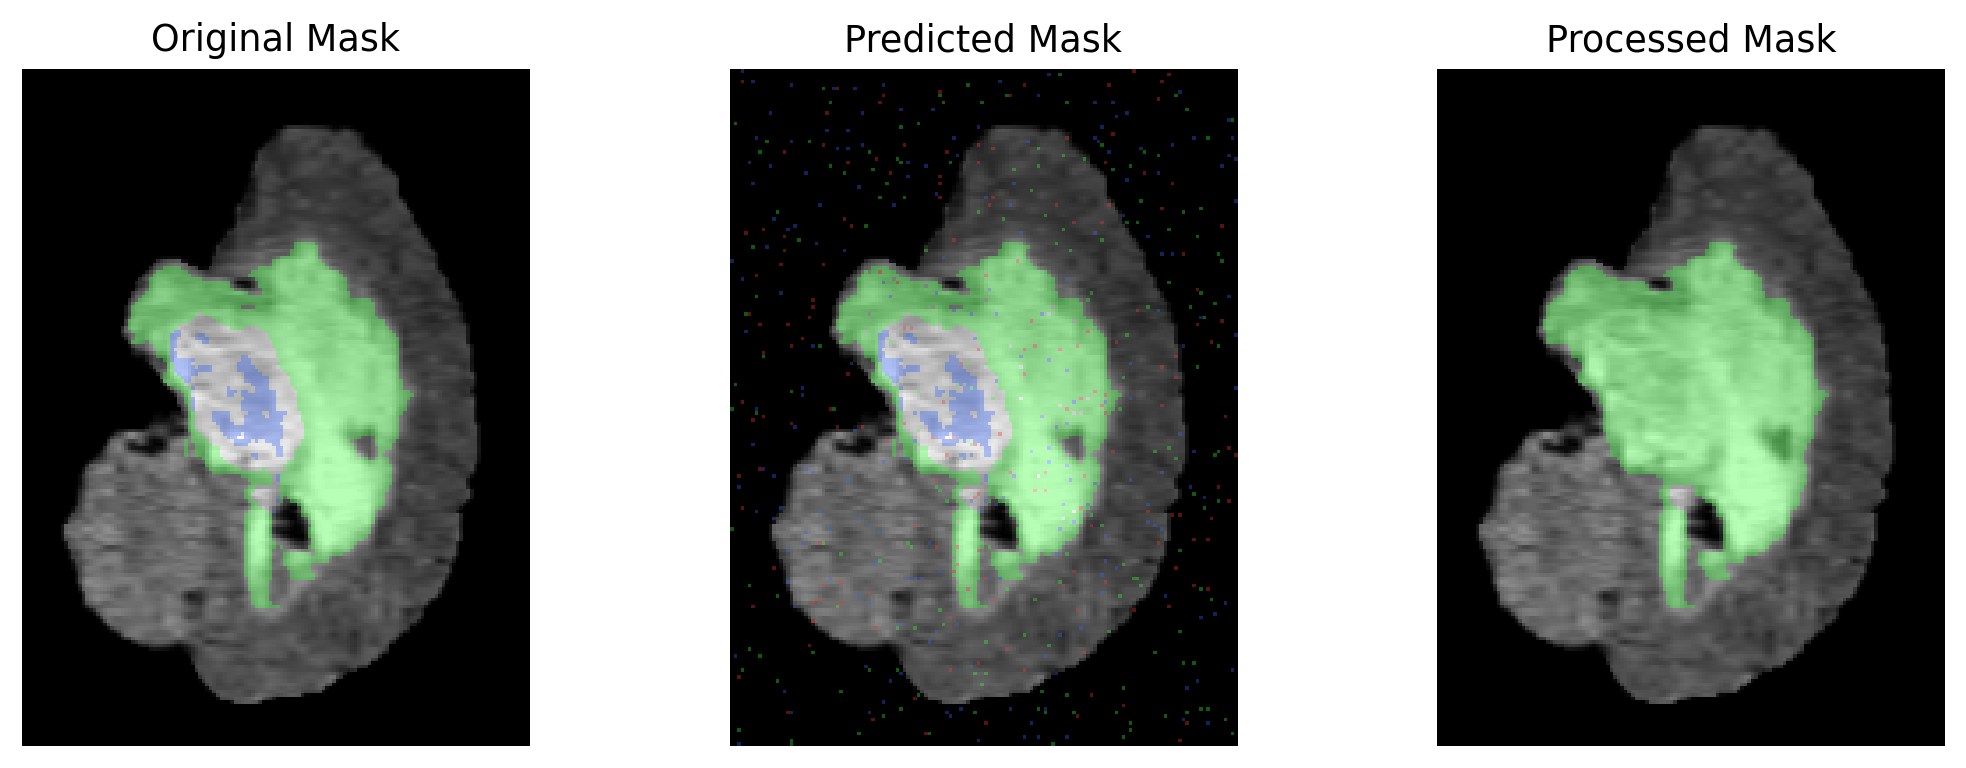

Saved to: /content/brats2021_training_process.png


In [ ]:
png = make_training_process_figure(save_path="/content/brats2021_training_process.png", pick_slice="max")
from IPython.display import Image, display
display(Image(png))
print("Saved to:", png)


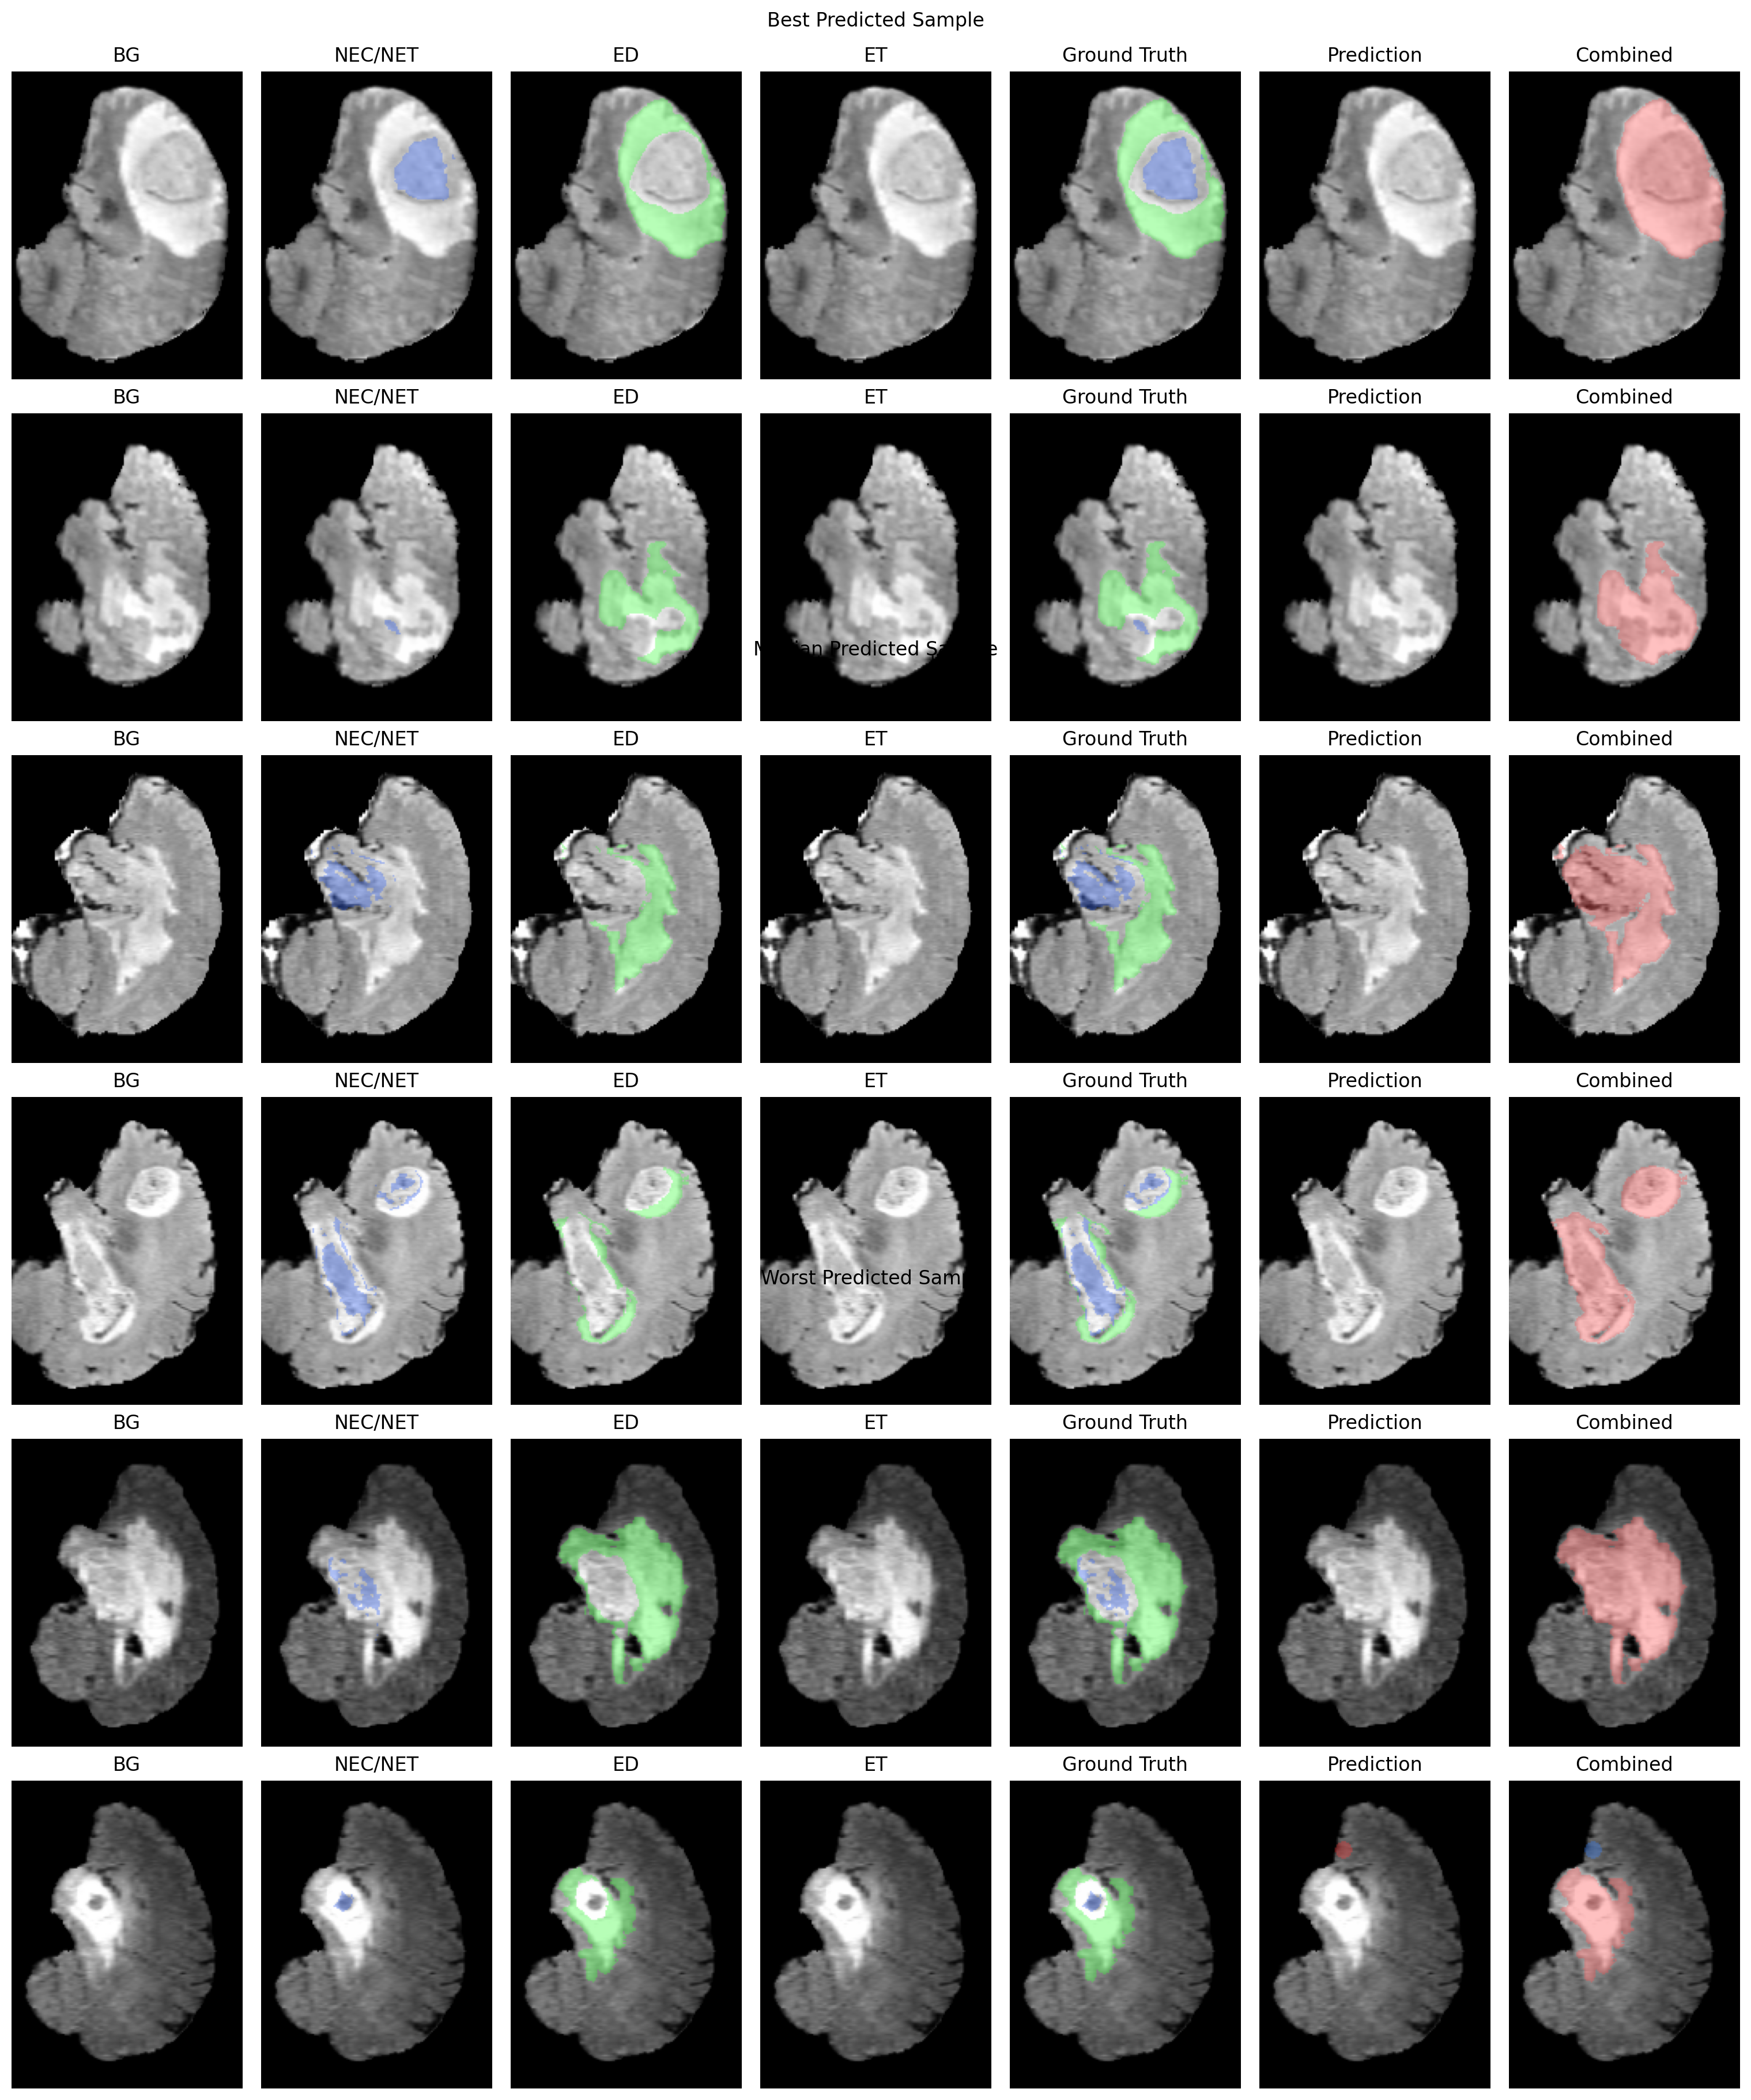

Saved to: /content/brats2021_bmw.png


In [ ]:
# ================== LOW-RAM BMW FIGURE FOR BRATS ==================
# Output: /content/brats2021_bmw.png

!pip -q install scipy

import os, glob, numpy as np, matplotlib.pyplot as plt, gc
from scipy.ndimage import label as cc_label, generate_binary_structure

# -------- CONFIG (ubah sesuai kebutuhan) --------
os.environ.setdefault("BRATS2021_OUT", "/content/brats2021_processed")  # folder *.npz
# os.environ["WEIGHTS"] = "/content/checkpoints/best.pt"               # optional
OUT_PATH      = "/content/brats2021_bmw.png"
K_PER_GROUP   = 2          # baris per grup
PATCH, STRIDE = 128, 96    # samakan dengan modelmu
USE_FP16      = True       # inference hemat memori
MAX_CASES     = 0          # 0 = pakai semua; >0 = batasi jumlah kasus untuk scanning

# -------- LOCATE DATA --------
def find_npz_root():
    cands = [
        os.environ.get("BRATS2021_OUT",""),
        os.environ.get("BRATS_OUT",""),
        "/content/brats2021_processed", "/content/brats_processed",
        "/mnt/data/brats2021_processed", "/mnt/data/brats_processed",
    ]
    for r in cands:
        if not r: continue
        ps = sorted(glob.glob(os.path.join(r, "*.npz")))
        if ps: return r, ps
    return None, []

# -------- UTILS (ringan) --------
COLOR_NCR = np.array([0.20,0.40,1.00])
COLOR_ED  = np.array([0.20,1.00,0.20])
COLOR_ET  = np.array([1.00,0.20,0.20])
ALPHA     = 0.35

def norm01(x):
    x = x.astype(np.float32)
    return (x - x.min()) / (x.max() - x.min() + 1e-6)

def overlay_rgb(bg, masks):
    rgb = np.stack([bg,bg,bg], axis=-1).copy()
    for m, color in masks:
        m = m.astype(bool)
        rgb[m] = (1-ALPHA)*rgb[m] + ALPHA*color
    return rgb

def dice_bin(y_true, y_pred):
    inter = (y_true & y_pred).sum()
    denom = y_true.sum() + y_pred.sum()
    return (2.0 * inter / max(1, denom)).item()

def dice_macro_3(gt, pr):
    return float(np.mean([dice_bin(gt==c, pr==c) for c in (1,2,3)]))

def best_tumor_slice(mask3d):
    areas = [(mask3d[z]>0).sum() for z in range(mask3d.shape[0])]
    return int(np.argmax(areas)) if max(areas)>0 else mask3d.shape[0]//2

# -------- MODEL INFERENCE (hemat memori) --------
def try_model_predict(img, patch=128, stride=96):
    """
    img: (C,D,H,W) float32
    return: (D,H,W) uint8 di {0,1,2,3}
    """
    try:
        import torch
        from infer_visualize import load_trained_model, sliding_window_predict  # sesuaikan modulmu
        DEVICE  = torch.device("cuda" if torch.cuda.is_available() else "cpu")
        weights = os.environ.get("WEIGHTS","")
        model   = load_trained_model(weights).to(DEVICE).eval()

        with torch.no_grad():
            x = torch.from_numpy(img[None,...])  # (1,C,D,H,W)
            if USE_FP16 and torch.cuda.is_available():
                with torch.cuda.amp.autocast(dtype=torch.float16):
                    x = x.to(DEVICE, non_blocking=True)
                    logits = sliding_window_predict(model, x, patch=patch, stride=stride)  # (1,4,D,H,W) on CPU
            else:
                x = x.to(DEVICE, non_blocking=True)
                logits = sliding_window_predict(model, x, patch=patch, stride=stride)

        pred = np.argmax(logits.numpy(), axis=1).squeeze(0).astype(np.uint8)

        # bersihkan
        del model, x, logits
        if 'torch' in globals():
            torch.cuda.empty_cache()
        gc.collect()
        return pred
    except Exception as e:
        # fallback simulasi (agar layout tetap jadi)
        rng = np.random.default_rng(123)
        lbl_shape = img.shape[1:]  # (D,H,W)
        pred = np.zeros(lbl_shape, dtype=np.uint8)
        # bikin dummy blob kecil per kelas
        D,H,W = lbl_shape
        for cls, r in zip([1,2,3],[10,12,8]):
            z = rng.integers(0, D); cy = rng.integers(r+5, H-r-5); cx = rng.integers(r+5, W-r-5)
            zz, yy, xx = np.ogrid[:D,:H,:W]
            mask = (zz-z)**2 + (yy-cy)**2 + (xx-cx)**2 <= r*r
            pred[mask] = cls
        return pred

# ================= PASS 1: SCAN & SCORE TANPA SIMPAN VOLUME =================
root, paths = find_npz_root()
assert paths, "NPZ tidak ditemukan. Set os.environ['BRATS2021_OUT'] ke folder NPZ kamu."

if MAX_CASES and MAX_CASES > 0:
    paths = paths[:MAX_CASES]

scores = []   # hanya [(score, path, z)]
for p in paths:
    d   = np.load(p, allow_pickle=False)
    lbl = d["label"].astype(np.uint8)    # (D,H,W) => kecil (<= ~9MB), aman
    z   = best_tumor_slice(lbl)

    # prediksi (model jalan sekali per kasus), langsung buang setelah dipakai
    img = d["image"].astype(np.float32)  # (C,D,H,W)
    pred= try_model_predict(img, patch=PATCH, stride=STRIDE)
    score = dice_macro_3(lbl, pred)

    scores.append((score, p, z))
    # bebasin memori
    del d, img, lbl, pred
    gc.collect()

# tentukan best/median/worst (pakai hanya metadata kecil)
scores.sort(key=lambda x: x[0])
n = len(scores)
best   = scores[-K_PER_GROUP:]
median = scores[max(0, n//2 - K_PER_GROUP//2): max(0, n//2 - K_PER_GROUP//2)+K_PER_GROUP]
worst  = scores[:K_PER_GROUP]

groups = [("Best Predicted Sample", best[::-1]),
          ("Median Predicted Sample", median),
          ("Worst Predicted Sample", worst)]

# ================= PASS 2: RENDER HANYA KASUS TERPILIH =================
COLS = 7
ROWS = sum(len(g[1]) for g in groups)
fig_w, fig_h = 2.2*COLS, 3.0*ROWS
fig, axes = plt.subplots(ROWS, COLS, figsize=(fig_w, fig_h))
if ROWS == 1: axes = np.expand_dims(axes, 0)

row = 0
for title, group in groups:
    fig.text(0.5, 1.0 - (row/(ROWS+0.6)), title, ha="center", va="bottom", fontsize=12)
    for score, p, z in group:
        d    = np.load(p, allow_pickle=False)
        img  = d["image"].astype(np.float32)
        lbl  = d["label"].astype(np.uint8)
        flair= img[3]
        pred = try_model_predict(img, patch=PATCH, stride=STRIDE)

        bg   = norm01(flair[z])
        gt2d = lbl[z]; pr2d = pred[z]

        # kolom 0: BG
        axes[row,0].imshow(bg, cmap="gray"); axes[row,0].set_title("BG"); axes[row,0].axis("off")
        # kolom 1..3: GT per kelas
        axes[row,1].imshow(overlay_rgb(bg, [(gt2d==1, COLOR_NCR)])); axes[row,1].set_title("NEC/NET"); axes[row,1].axis("off")
        axes[row,2].imshow(overlay_rgb(bg, [(gt2d==2, COLOR_ED)]));  axes[row,2].set_title("ED");      axes[row,2].axis("off")
        axes[row,3].imshow(overlay_rgb(bg, [(gt2d==3, COLOR_ET)]));  axes[row,3].set_title("ET");      axes[row,3].axis("off")
        # kolom 4: GT all
        axes[row,4].imshow(overlay_rgb(bg, [(gt2d==1,COLOR_NCR),(gt2d==2,COLOR_ED),(gt2d==3,COLOR_ET)]))
        axes[row,4].set_title("Ground Truth"); axes[row,4].axis("off")
        # kolom 5: Pred all
        axes[row,5].imshow(overlay_rgb(bg, [(pr2d==1,COLOR_NCR),(pr2d==2,COLOR_ED),(pr2d==3,COLOR_ET)]))
        axes[row,5].set_title("Prediction"); axes[row,5].axis("off")
        # kolom 6: Combined TP/FP/FN
        gt_bin, pr_bin = gt2d>0, pr2d>0
        tp = gt_bin & pr_bin; fn = gt_bin & (~pr_bin); fp = (~gt_bin) & pr_bin
        comb = np.stack([bg,bg,bg], axis=-1).copy()
        comb[tp] = (1-ALPHA)*comb[tp] + ALPHA*np.array([0.20,1.00,0.20])
        comb[fn] = (1-ALPHA)*comb[fn] + ALPHA*np.array([1.00,0.30,0.30])
        comb[fp] = (1-ALPHA)*comb[fp] + ALPHA*np.array([0.20,0.50,1.00])
        axes[row,6].imshow(comb); axes[row,6].set_title("Combined"); axes[row,6].axis("off")

        # bebasin memori secepatnya
        del d, img, lbl, pred, flair, gt2d, pr2d, bg, comb
        gc.collect()
        row += 1

plt.tight_layout(h_pad=0.8, w_pad=0.4)
os.makedirs(os.path.dirname(OUT_PATH), exist_ok=True)
plt.savefig(OUT_PATH, dpi=200, bbox_inches="tight"); plt.close(fig)

from IPython.display import Image, display
display(Image(OUT_PATH))
print("Saved to:", OUT_PATH)
# ================================================================


[INFO] FIGS_DIR: /content/figs
[INFO] Jumlah gambar ditemukan: 4

Menampilkan 4 gambar pertama (preview cepat):


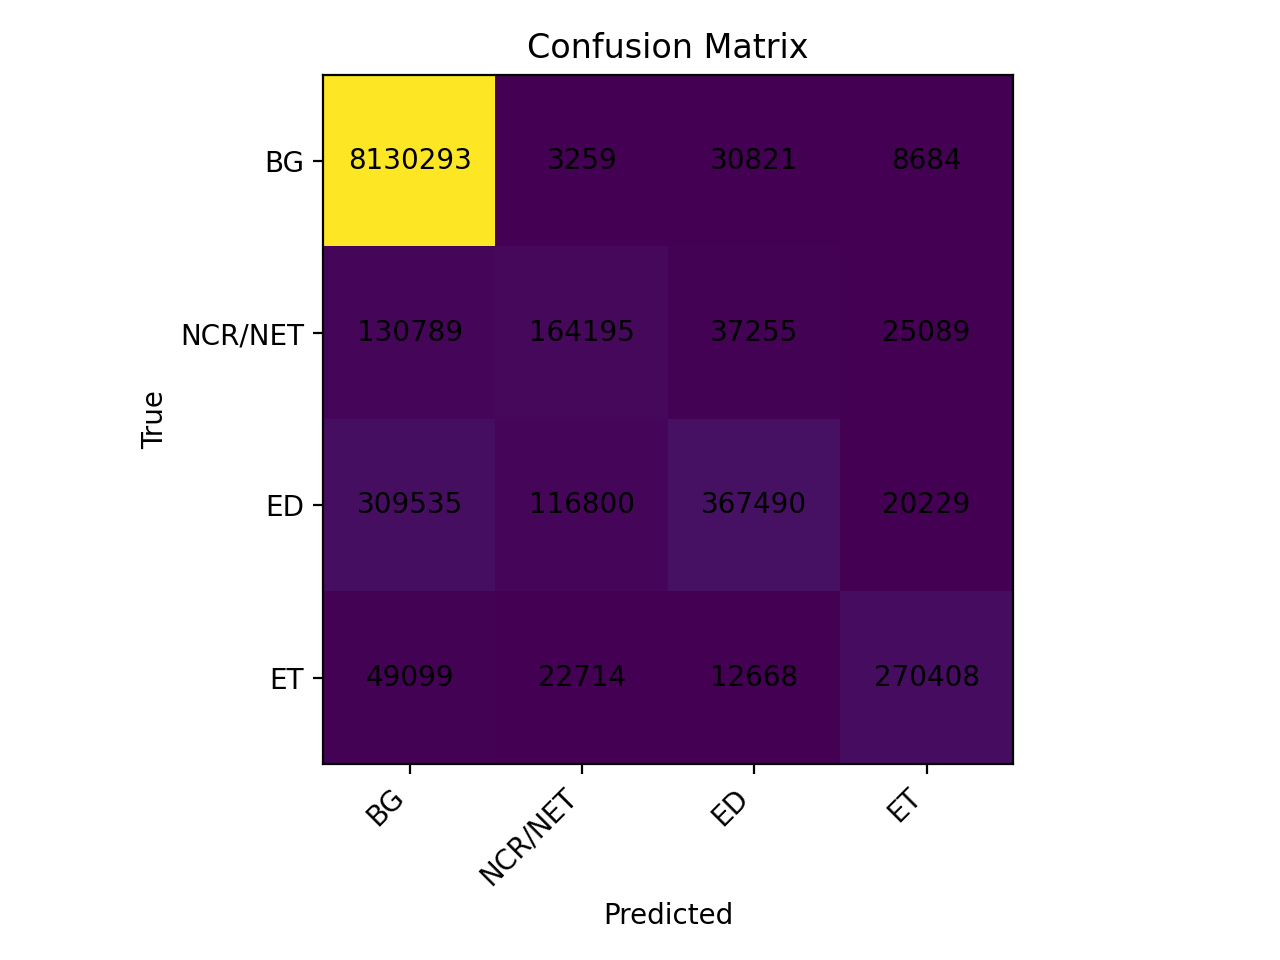

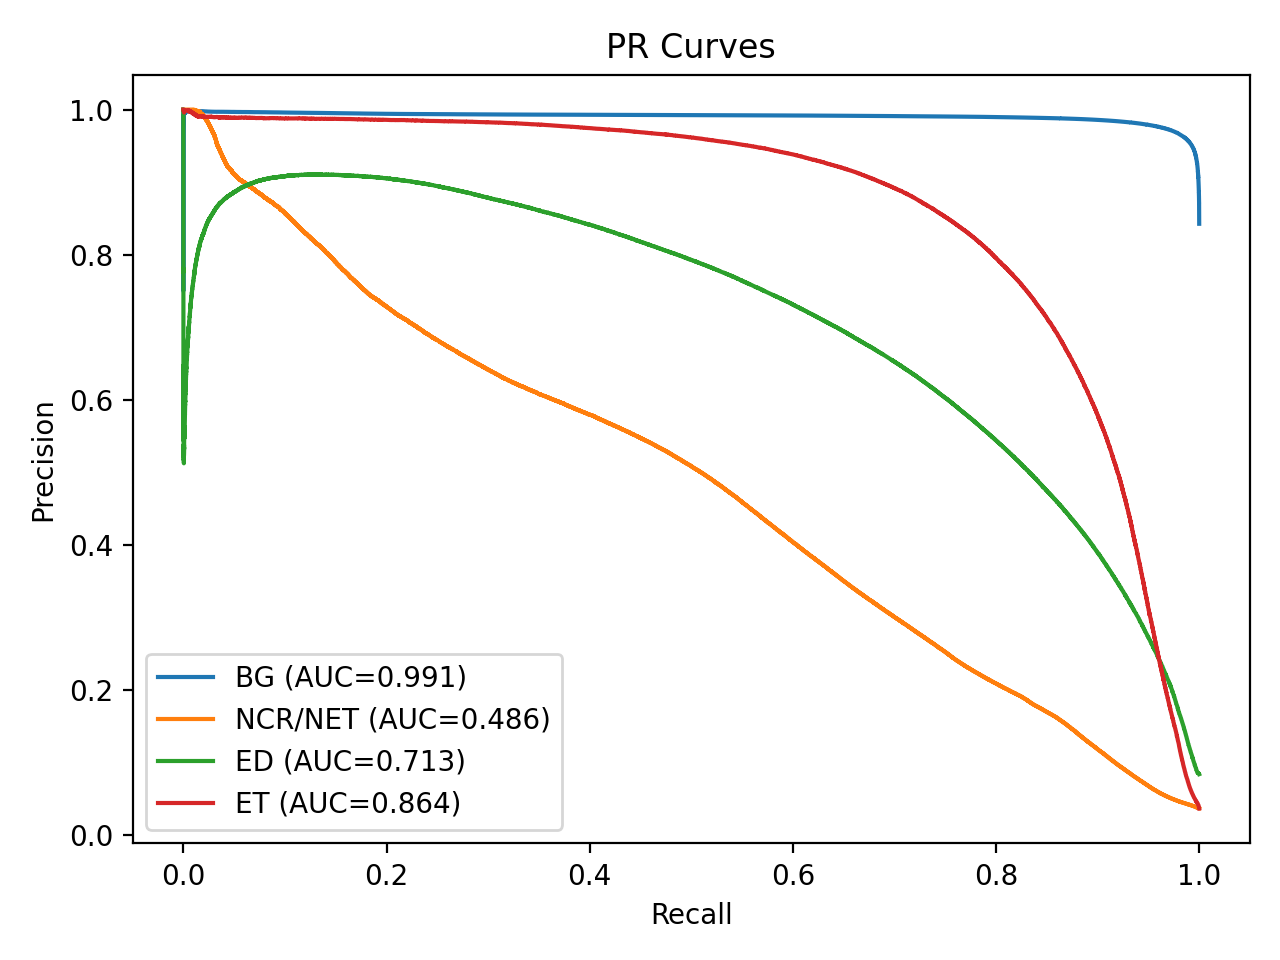

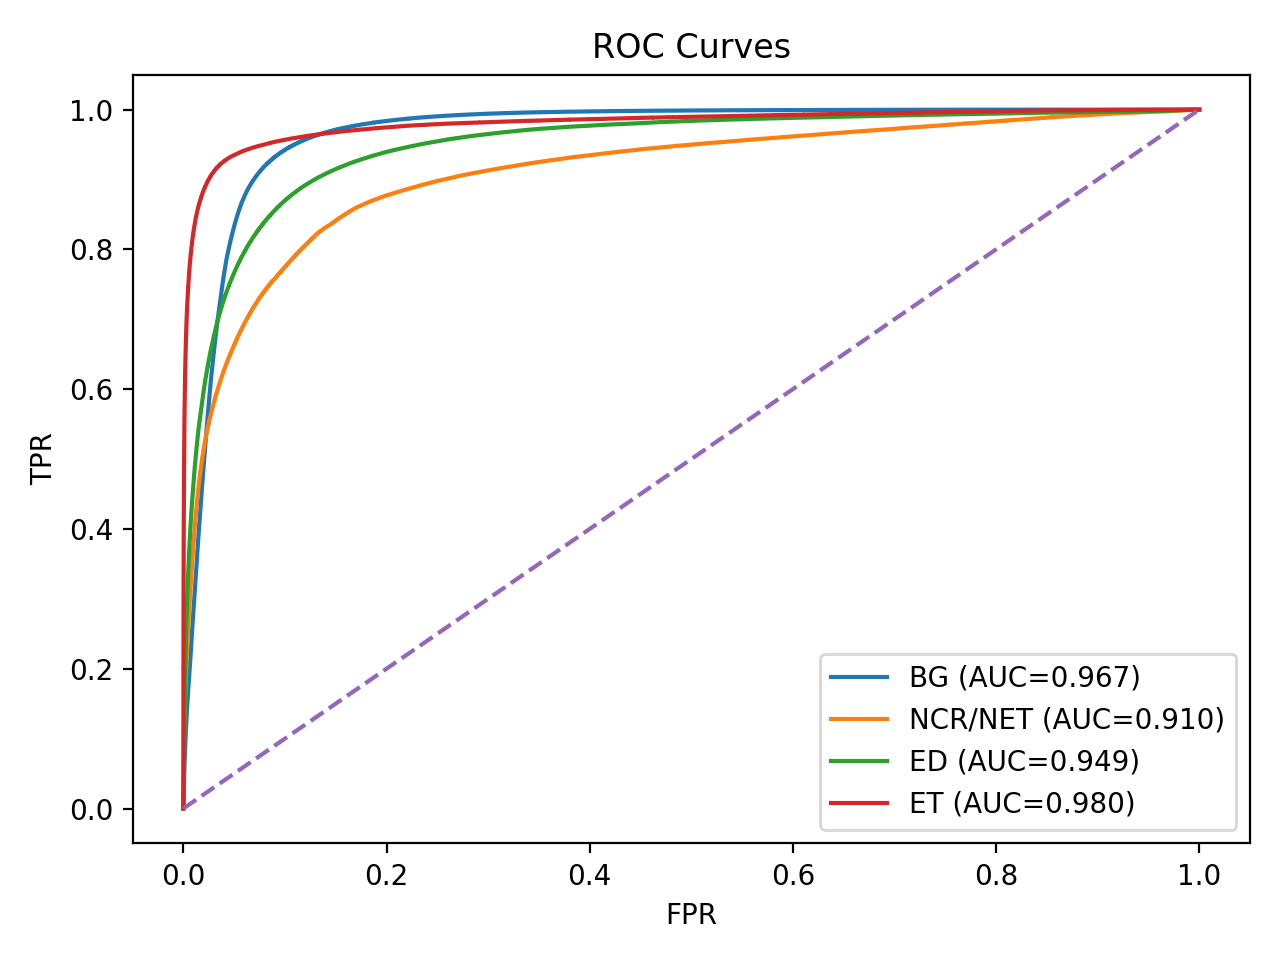

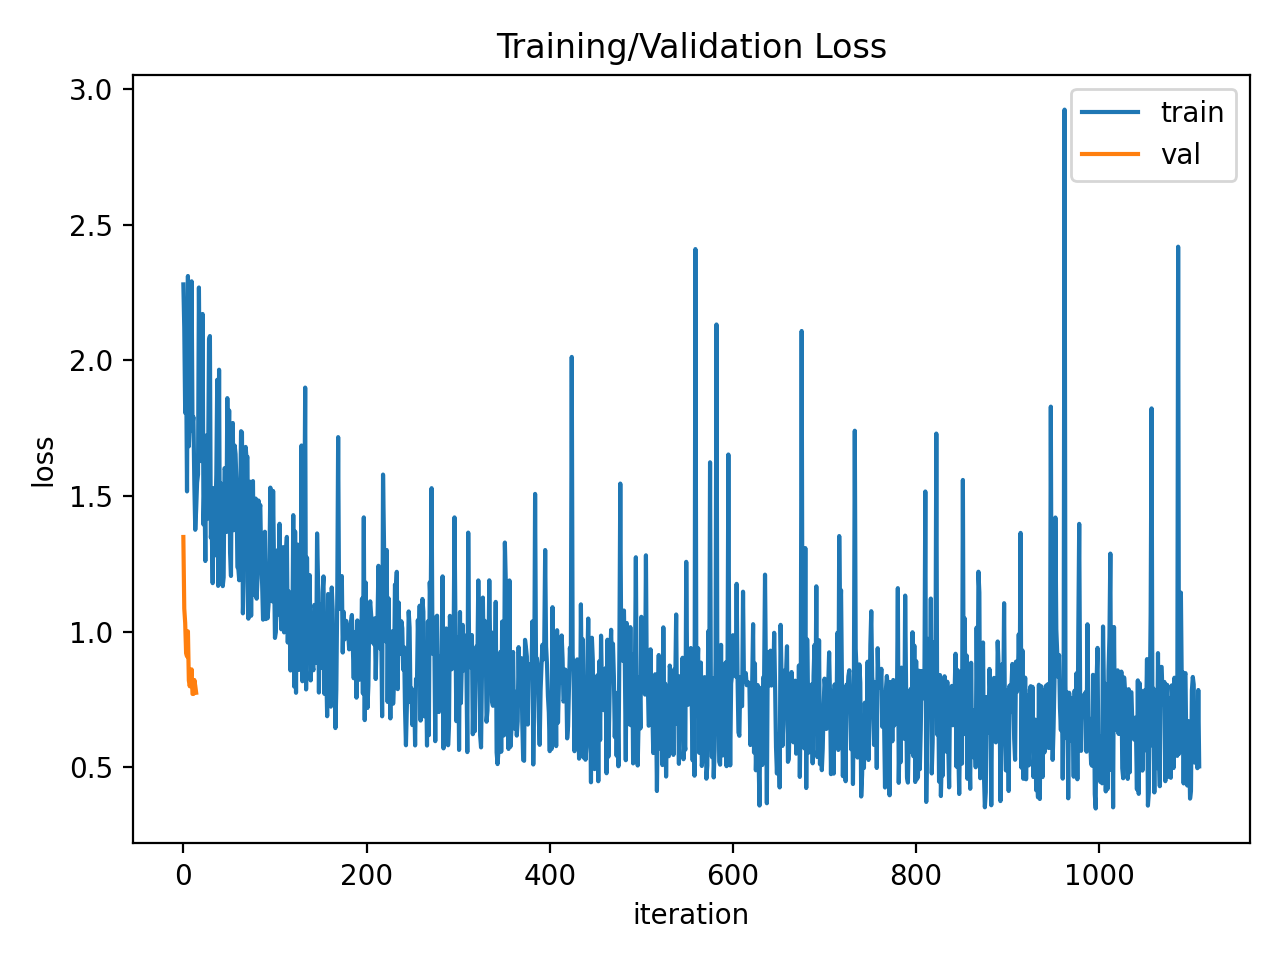

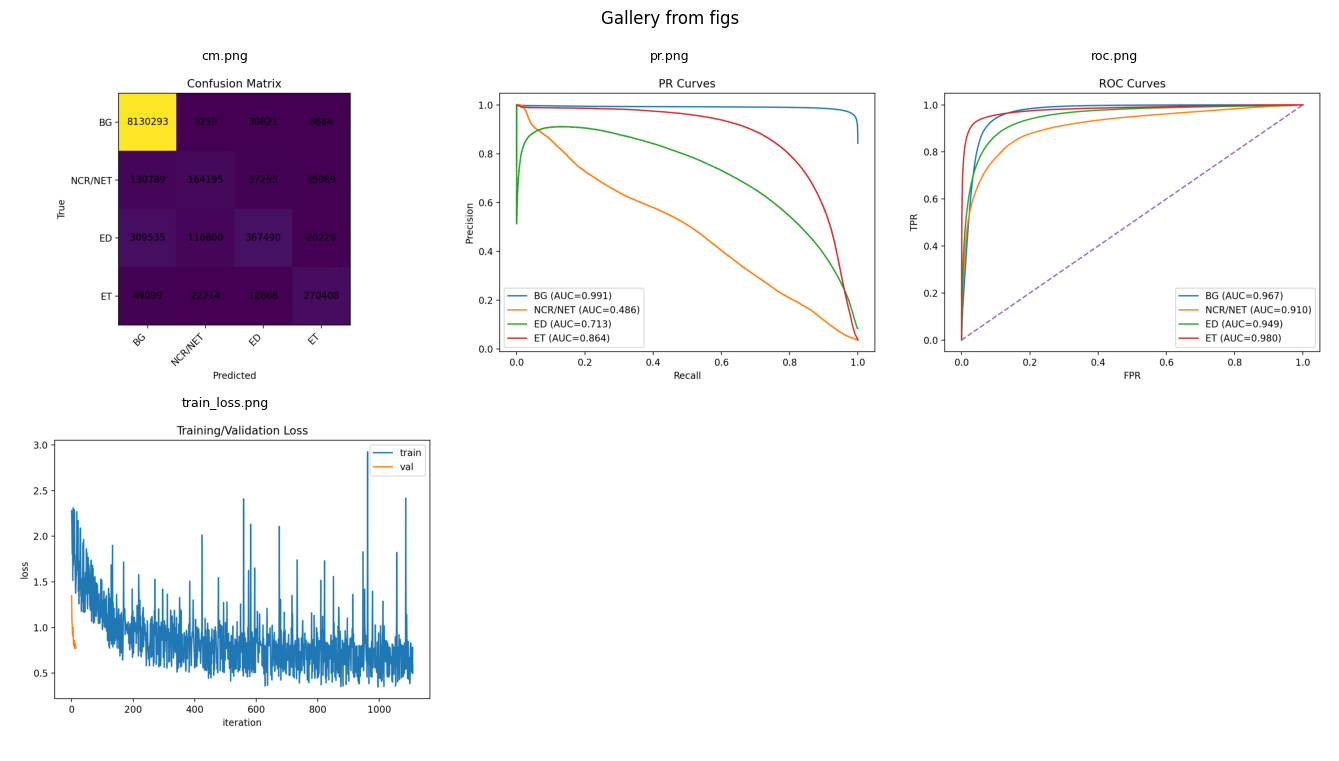


[OK] Galeri disimpan ke: /content/figs_gallery.png


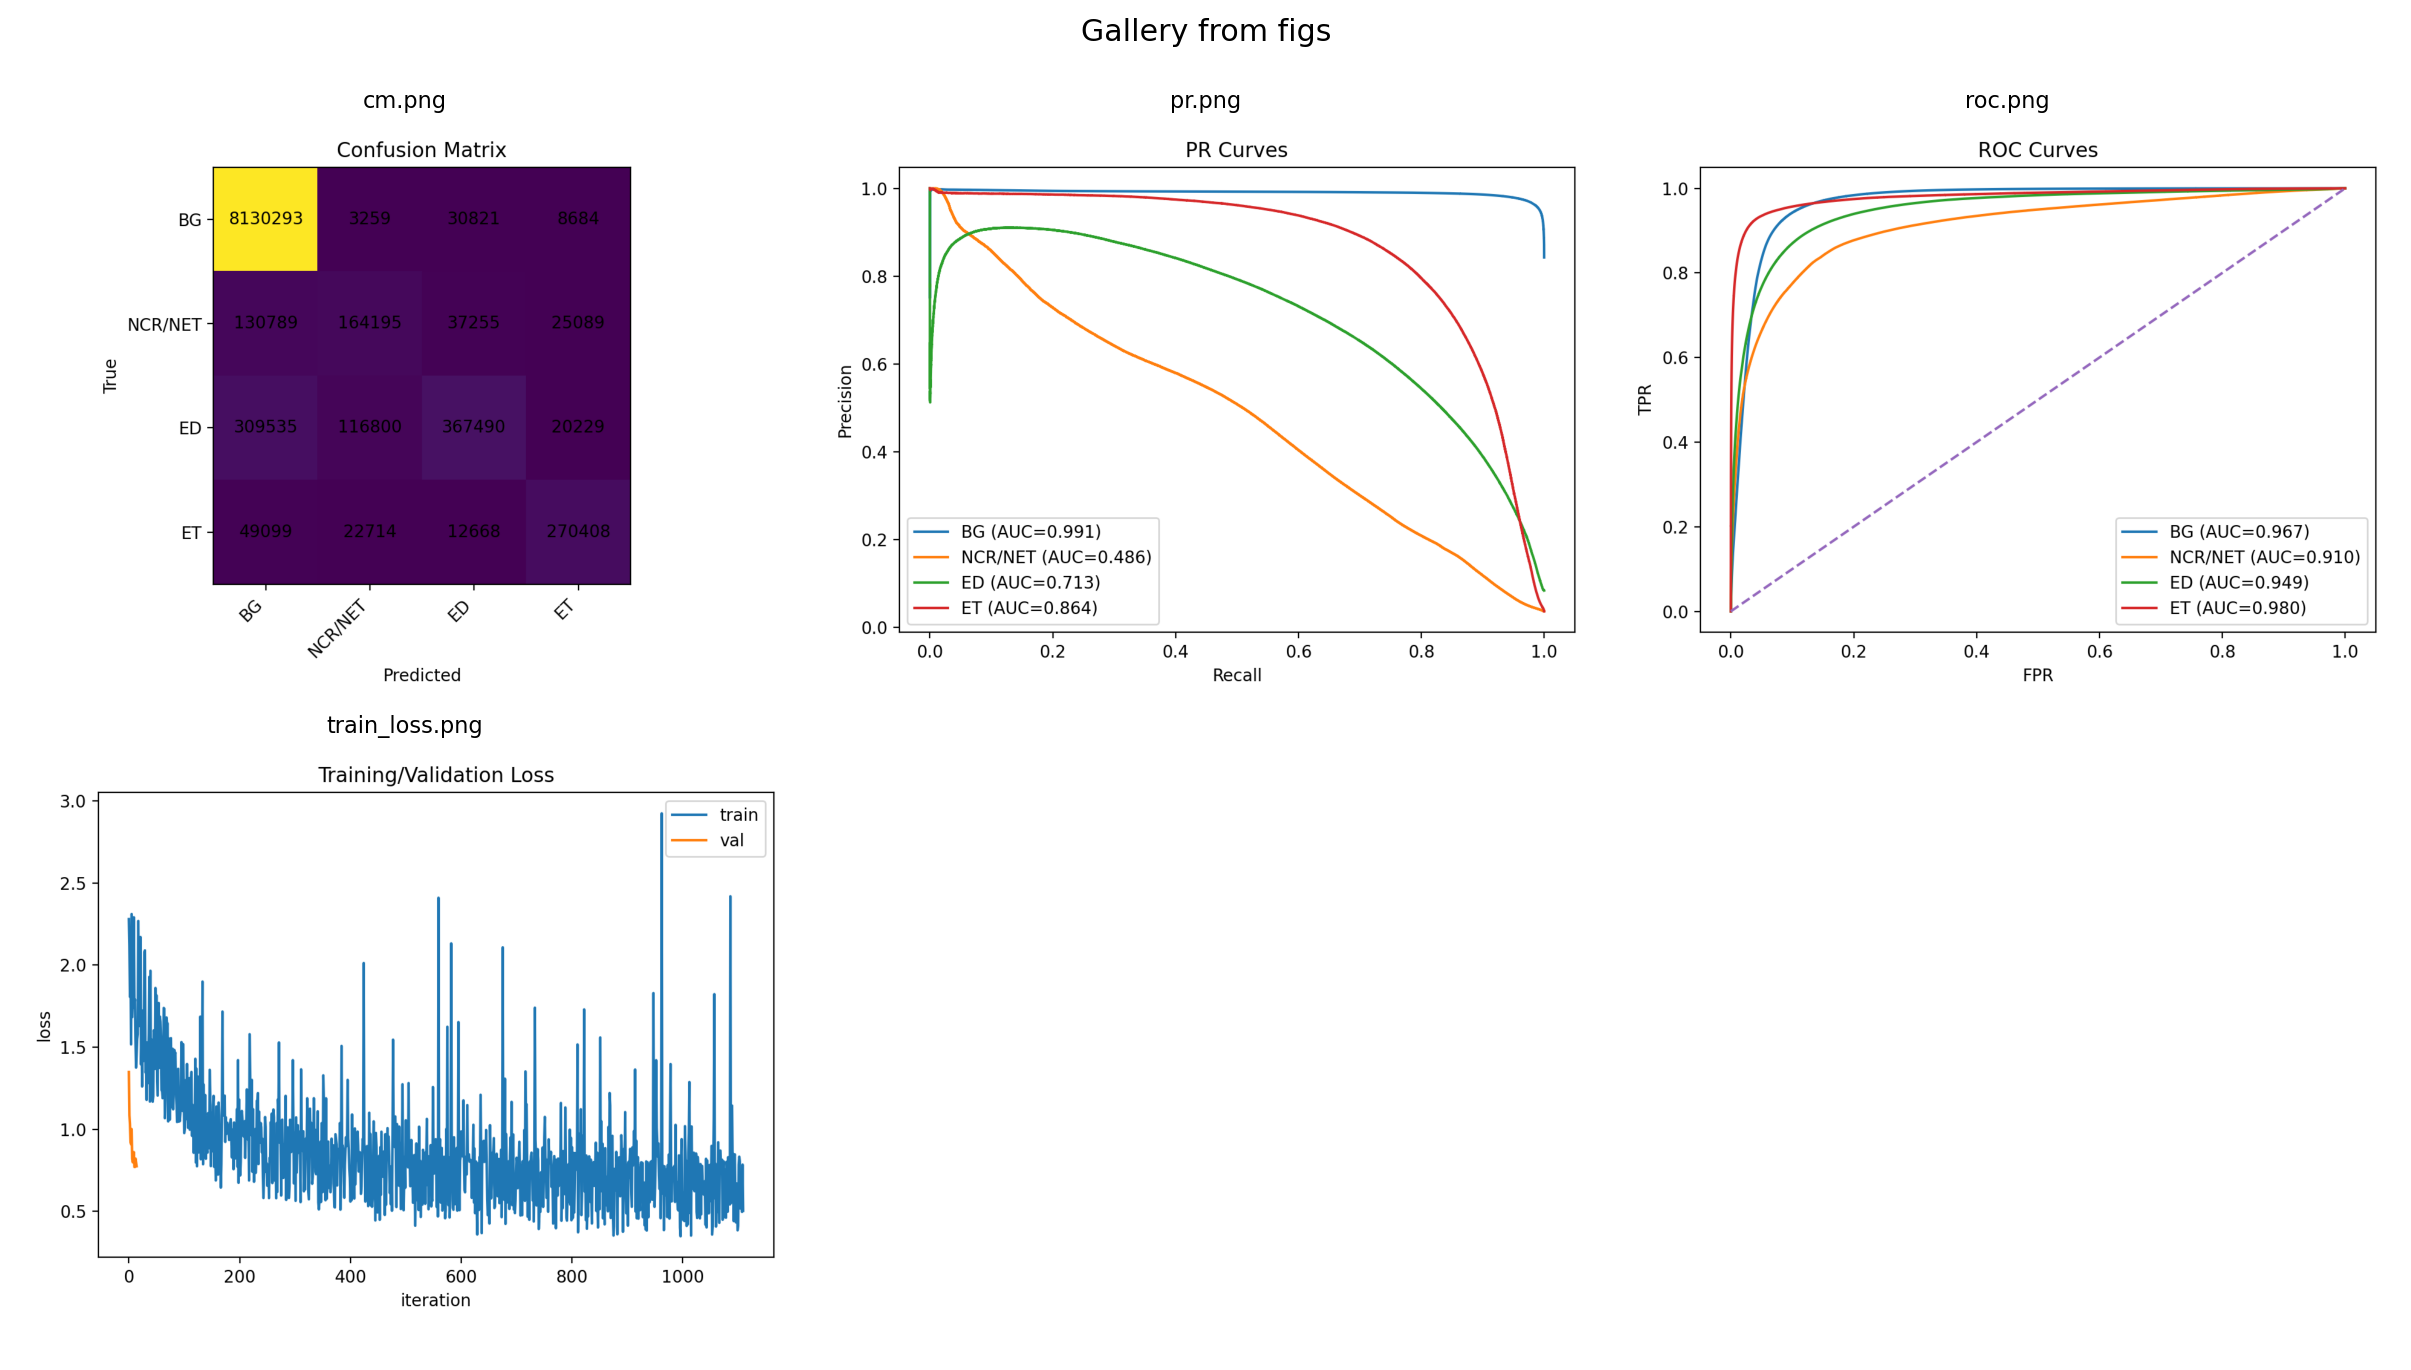

In [ ]:
# ==== DIAGNOSE & SHOW FIGURES FROM FOLDER ====
from pathlib import Path
import os, math
from PIL import Image
import matplotlib.pyplot as plt
from IPython.display import display, Image as IPyImage

# 1) SET PATH FIGS
FIGS_DIR = Path("/content/figs")  # <-- GANTI sesuai lokasi kamu
assert FIGS_DIR.exists(), f"Folder tidak ditemukan: {FIGS_DIR}"

# 2) CARI FILE GAMBAR
EXTS = {".png", ".jpg", ".jpeg", ".webp", ".tif", ".tiff", ".bmp"}
files = sorted([p for p in FIGS_DIR.rglob("*") if p.suffix.lower() in EXTS])

print(f"[INFO] FIGS_DIR: {FIGS_DIR.resolve()}")
print(f"[INFO] Jumlah gambar ditemukan: {len(files)}")
if len(files) == 0:
    print(">> Folder kosong atau ekstensi tidak cocok. Pastikan gambar disimpan sebagai PNG/JPG/TIFF, dst.")
else:
    # 3) TAMPILKAN 4 GAMBAR PERTAMA LANGSUNG (paling aman di Colab)
    print("\nMenampilkan 4 gambar pertama (preview cepat):")
    for p in files[:4]:
        display(IPyImage(filename=str(p)))

    # 4) BUAT GALERI PADA CANVAS MATPLOTLIB + SIMPAN KE FILE
    cols = 3
    rows = math.ceil(min(len(files), 12) / cols)  # batasi 12 biar ringan
    fig, axes = plt.subplots(rows, cols, figsize=(4.5*cols, 3.8*rows))
    axes = (axes.ravel() if hasattr(axes, "ravel") else [axes])

    for i, ax in enumerate(axes):
        ax.axis("off")
        if i < min(len(files), rows*cols):
            img = Image.open(files[i]).convert("RGB")
            ax.imshow(img)
            ax.set_title(files[i].name, fontsize=9)

    plt.suptitle(f"Gallery from {FIGS_DIR.name}", y=0.995, fontsize=12)
    plt.tight_layout()
    out_png = "/content/figs_gallery.png"
    plt.savefig(out_png, dpi=180, bbox_inches="tight")
    plt.show(); plt.close(fig)

    print(f"\n[OK] Galeri disimpan ke: {out_png}")
    display(IPyImage(filename=out_png))
